In [1]:
%pip install numpy pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load raw dataset
df_raw = pd.read_csv("content/raw/raw_automotive_sales_data.csv")
print(f"Initial Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

# Baseline audit
initial_duplicates = df_raw.duplicated().sum()
initial_nulls = df_raw.isnull().sum().sum()
print(f"Raw Duplicates: {initial_duplicates} | Raw Total Nulls: {initial_nulls}")

df_raw.info()
df_raw.head()

Initial Dataset Shape: 6135 rows, 15 columns
Raw Duplicates: 135 | Raw Total Nulls: 1996
<class 'pandas.DataFrame'>
RangeIndex: 6135 entries, 0 to 6134
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Transaction_Reference_No    6135 non-null   str    
 1   Sale Date                   6135 non-null   str    
 2   Vehicle_Model               6135 non-null   str    
 3   Powertrain / Fuel           6135 non-null   str    
 4   Engine_or_Battery_Capacity  6135 non-null   str    
 5   Body_Style                  6135 non-null   str    
 6   Transmission_Type           6135 non-null   str    
 7   Mfg_Year                    6135 non-null   int64  
 8   Odometer_Reading            5979 non-null   str    
 9   Original_MRP (INR)          6043 non-null   str    
 10  Fleet_Discount_Rate         6135 non-null   float64
 11  Warranty_Period_Years       6135 non-null   int64  
 12  Sales_Region

,Transaction_Reference_No,Sale Date,Vehicle_Model,Powertrain / Fuel,Engine_or_Battery_Capacity,Body_Style,Transmission_Type,Mfg_Year,Odometer_Reading,Original_MRP (INR),Fleet_Discount_Rate,Warranty_Period_Years,Sales_Region,Buyer_Category,Final_Selling_Price
0,AUTO-31002,02-16-2022,Hyundai Creta,petrol,1500 cc,Compact SUV,Automatic,2024,"10,449 km","₹4,291,191.03",0.12,1,south,Rental Agency,3416087.93
1,AUTO-32913,03-27-2023,Maruti Grand Vitara,Hybrid,1500 cc,Mid SUV,Manual,2019,124323.0,"₹3,717,398.08",0.03,2,South Hub,Individual,1351171.33
2,AUTO-31983,24/03/2022,Honda City,petrol,1500 cc,Sedan,Automatic,2024,"19,782 km","₹1,687,913.04",0.08,2,South Hub,Individual,1338571.96
3,AUTO-30501,13-Nov-2022,Mahindra XUV700,DIESEL,2200 cc,Full SUV,Automatic,2024,"19,154 km","₹3,657,631.20",0.08,1,East Hub,Government Fleet,2982753.07
4,AUTO-30676,11/02/2024,Hyundai Creta,Petrol,1500 cc,Compact SUV,Manual,2024,"11,627 km","₹2,527,338.32",0.12,3,West Hub,Rental Agency,1999848.42


In [2]:
df_cleaned = df_raw.copy()

# 1. Drop duplicate rows
df_cleaned = df_cleaned.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {df_cleaned.shape}")

# 2. Standardize column names to snake_case
def clean_column_name(col):
    col = re.sub(r'[^\w\s]', '', col) # Strip symbols like () and /
    col = re.sub(r'[\s\-]+', '_', col) # Replace spaces/hyphens with underscore
    return col.strip('_').lower()

df_cleaned.columns = [clean_column_name(c) for c in df_cleaned.columns]
print("\nCleaned Column Names:")
print(list(df_cleaned.columns))

Shape after removing duplicates: (6000, 15)

Cleaned Column Names:
['transaction_reference_no', 'sale_date', 'vehicle_model', 'powertrain_fuel', 'engine_or_battery_capacity', 'body_style', 'transmission_type', 'mfg_year', 'odometer_reading', 'original_mrp_inr', 'fleet_discount_rate', 'warranty_period_years', 'sales_region', 'buyer_category', 'final_selling_price']


In [3]:
# 1. Clean Currency in 'original_mrp_inr'
def clean_currency(val):
    if pd.isnull(val):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    cleaned = re.sub(r'[₹$,\s]', '', str(val))
    return float(cleaned) if cleaned else np.nan

df_cleaned['original_mrp_inr'] = df_cleaned['original_mrp_inr'].apply(clean_currency)

# 2. Clean 'odometer_reading' (strip 'km', commas)
def clean_odometer(val):
    if pd.isnull(val):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    cleaned = re.sub(r'[^\d.]', '', str(val))
    return float(cleaned) if cleaned else np.nan

df_cleaned['odometer_reading'] = df_cleaned['odometer_reading'].apply(clean_odometer)

# 3. Parse mixed format transaction dates
df_cleaned['sale_date'] = pd.to_datetime(df_cleaned['sale_date'], format='mixed')

print("Data types after conversion:")
print(df_cleaned[['original_mrp_inr', 'odometer_reading', 'sale_date']].dtypes)

Data types after conversion:
original_mrp_inr           float64
odometer_reading           float64
sale_date           datetime64[us]
dtype: object


In [4]:
# Harmonize powertrain/fuel types
fuel_map = {
    'electric': 'Electric', 'EV': 'Electric', 'Electric': 'Electric', 'battery_ev': 'Electric',
    'hybrid': 'Hybrid', 'Hybrid': 'Hybrid', 'HEV': 'Hybrid',
    'petrol': 'Petrol', 'Petrol': 'Petrol', 'Gasoline': 'Petrol',
    'diesel': 'Diesel', 'Diesel': 'Diesel', 'DIESEL': 'Diesel'
}
df_cleaned['powertrain_fuel'] = df_cleaned['powertrain_fuel'].map(fuel_map)

# Harmonize sales regions
region_map = {
    'North Hub': 'North Hub', 'north hub': 'North Hub',
    'West Hub': 'West Hub', 'WEST': 'West Hub',
    'South Hub': 'South Hub', 'south': 'South Hub',
    'East Hub': 'East Hub'
}
df_cleaned['sales_region'] = df_cleaned['sales_region'].map(region_map)

In [5]:
# Drop rows where target variable is missing
df_cleaned = df_cleaned.dropna(subset=['final_selling_price']).reset_index(drop=True)

# Impute categorical variables
df_cleaned['buyer_category'] = df_cleaned['buyer_category'].fillna('Individual')
df_cleaned['sales_region'] = df_cleaned['sales_region'].fillna(df_cleaned['sales_region'].mode()[0])

# Impute numerical features using median
num_imputes = ['odometer_reading', 'original_mrp_inr']
for col in num_imputes:
    df_cleaned[col] = df_cleaned[col].fillna(df_cleaned[col].median())

print(f"Remaining Missing Values: {df_cleaned.isnull().sum().sum()}")

Remaining Missing Values: 0


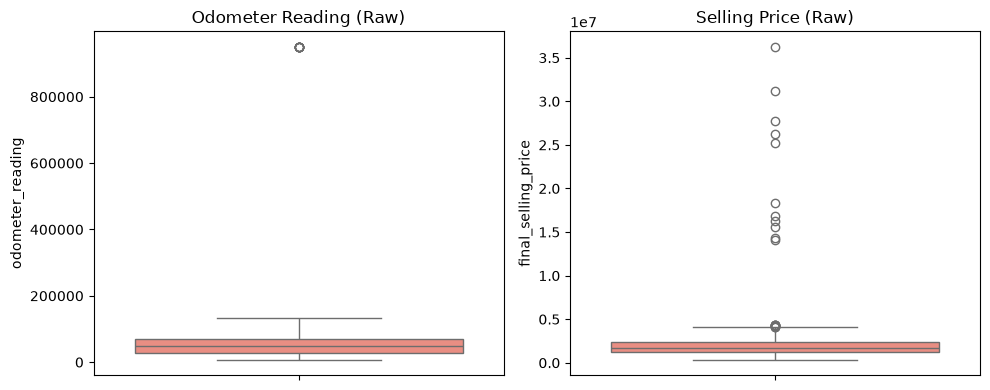

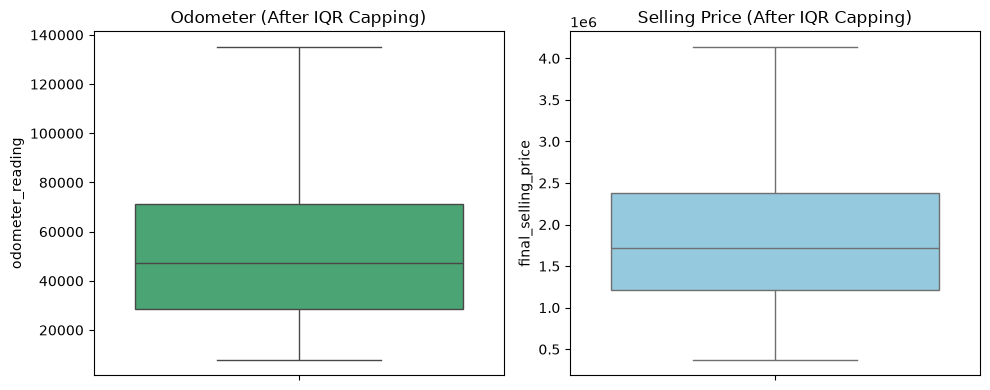

In [6]:
outlier_targets = ['odometer_reading', 'final_selling_price']

# Visual comparison before capping
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(y=df_cleaned['odometer_reading'], color='salmon')
plt.title("Odometer Reading (Raw)")

plt.subplot(1, 2, 2)
sns.boxplot(y=df_cleaned['final_selling_price'], color='salmon')
plt.title("Selling Price (Raw)")
plt.tight_layout()
plt.show()

# Apply IQR Capping
for col in outlier_targets:
    q1 = df_cleaned[col].quantile(0.25)
    q3 = df_cleaned[col].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    
    # Cap values beyond bounds
    df_cleaned[col] = np.clip(df_cleaned[col], lower_limit, upper_limit)

# Visual check after capping
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(y=df_cleaned['odometer_reading'], color='mediumseagreen')
plt.title("Odometer (After IQR Capping)")

plt.subplot(1, 2, 2)
sns.boxplot(y=df_cleaned['final_selling_price'], color='skyblue')
plt.title("Selling Price (After IQR Capping)")
plt.tight_layout()
plt.show()

In [7]:
# Validation asserts
assert df_cleaned.isnull().sum().sum() == 0, "Nulls remain in dataset!"
assert df_cleaned.duplicated().sum() == 0, "Duplicates remain in dataset!"

# Export cleaned data
output_path = "content\processed\cleaned_automotive_sales_data.csv"
df_cleaned.to_csv(output_path, index=False)
print(f"Cleaned dataset saved to: {output_path}")

# Before/After Audit Table
audit_df = pd.DataFrame({
    "Data Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Total Missing Values",
        "Max Odometer (km)",
        "Max Selling Price (₹)"
    ],
    "Raw Dataset": [
        len(df_raw),
        df_raw.shape[1],
        int(initial_duplicates),
        int(initial_nulls),
        f"{float(re.sub(r'[^\d.]', '', str(df_raw['Odometer_Reading'].dropna().iloc[0]))):,.0f} (est)",
        f"{df_raw['Final_Selling_Price'].max():,.2f}"
    ],
    "Cleaned Dataset": [
        len(df_cleaned),
        df_cleaned.shape[1],
        int(df_cleaned.duplicated().sum()),
        int(df_cleaned.isnull().sum().sum()),
        f"{df_cleaned['odometer_reading'].max():,.0f}",
        f"{df_cleaned['final_selling_price'].max():,.2f}"
    ]
})

display(audit_df)

Cleaned dataset saved to: content\processed\cleaned_automotive_sales_data.csv


<>:6: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:6: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\Gaurav\AppData\Local\Temp\ipykernel_15760\1355585152.py:6: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  output_path = "content\processed\cleaned_automotive_sales_data.csv"


,Data Metric,Raw Dataset,Cleaned Dataset
0,Total Rows,6135,5880
1,Total Columns,15,15
2,Duplicate Rows,135,0
3,Total Missing Values,1996,0
4,Max Odometer (km),"10,449 (est)","135,114"
5,Max Selling Price (₹),"36,241,699.80","4,137,232.37"


In [8]:
# ------------------------------------------------------------------------------
# STEP 2: SUMMARY STATISTICS
# ------------------------------------------------------------------------------
# Numeric descriptive statistics (mean, median, std, IQR)
num_cols = df_cleaned.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_cleaned.select_dtypes(include=["object", "category"]).columns.tolist()

print("--- NUMERICAL SUMMARY STATISTICS ---")
display(df_cleaned[num_cols].describe().T)

if cat_cols:
    print("\n--- CATEGORICAL SUMMARY STATISTICS ---")
    display(df_cleaned[cat_cols].describe().T)

--- NUMERICAL SUMMARY STATISTICS ---


C:\Users\Gaurav\AppData\Local\Temp\ipykernel_15760\3864884076.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_cleaned.select_dtypes(include=["object", "category"]).columns.tolist()


,count,mean,std,min,25%,50%,75%,max
mfg_year,5880.0,2.021508e+03,1.713720,2019.00,2.020000e+03,2022.000,2023.00,2024.000
odometer_reading,5880.0,5.228807e+04,29861.049776,8014.00,2.870475e+04,47460.000,71268.50,135114.125
original_mrp_inr,5880.0,2.844401e+06,945293.290994,1200611.14,2.050749e+06,2853634.895,3651892.51,4499502.510
fleet_discount_rate,5880.0,7.184014e-02,0.050960,0.00,3.000000e-02,0.080,0.12,0.150
warranty_period_years,5880.0,2.739966e+00,1.499981,1.00,1.000000e+00,2.000,5.00,5.000
final_selling_price,5880.0,1.842205e+06,797997.626772,376180.32,1.216704e+06,1712098.340,2384915.54,4137232.370



--- CATEGORICAL SUMMARY STATISTICS ---


,count,unique,top,freq
transaction_reference_no,5880,5880,AUTO-31002,1
vehicle_model,5880,8,Hyundai Ioniq 5,803
powertrain_fuel,5880,4,Electric,2307
engine_or_battery_capacity,5880,6,1500 cc,2178
body_style,5880,6,Compact SUV,1495
transmission_type,5880,2,Manual,2992
sales_region,5880,4,West Hub,1810
buyer_category,5880,4,Individual,2501


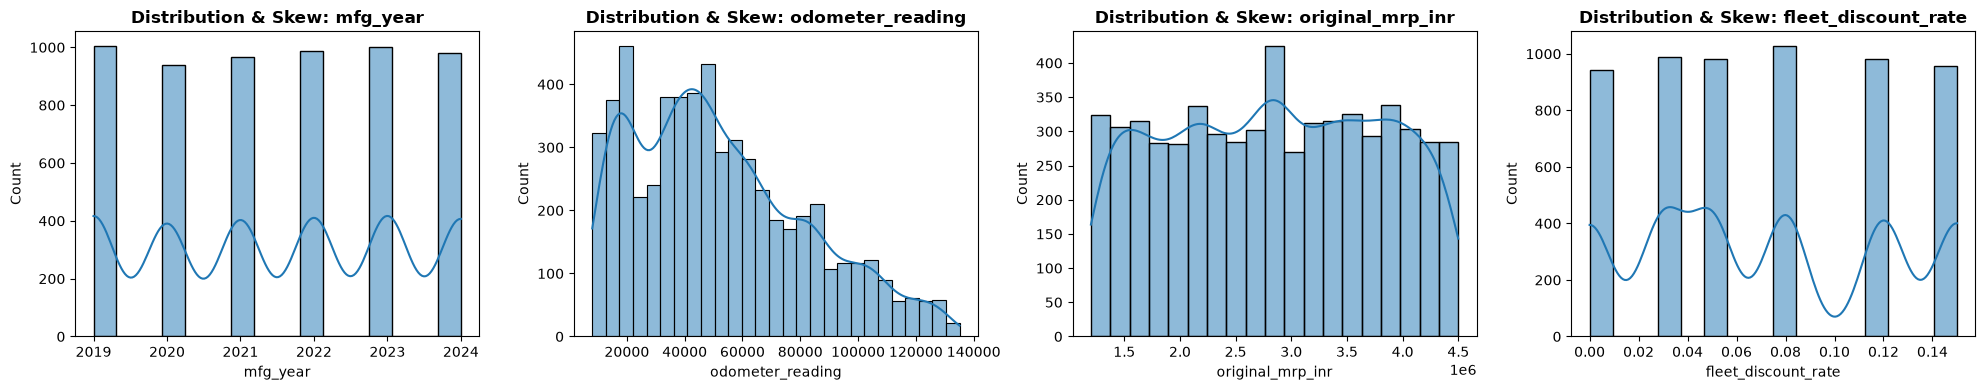

C:\Users\Gaurav\AppData\Local\Temp\ipykernel_15760\2487922716.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


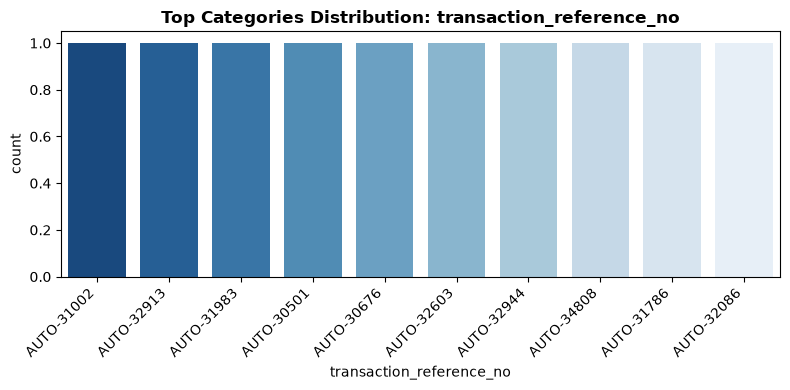

In [9]:
# ------------------------------------------------------------------------------
# STEP 3: UNIVARIATE ANALYSIS (DISTRIBUTIONS)
# ------------------------------------------------------------------------------
# 1. Histograms + KDE for primary numerical columns (up to 4)
cols_to_plot = num_cols[:4] if len(num_cols) >= 4 else num_cols
if cols_to_plot:
    fig, axes = plt.subplots(nrows=1, ncols=len(cols_to_plot), figsize=(5 * len(cols_to_plot), 4))
    if len(cols_to_plot) == 1:
        axes = [axes]
    for ax, col in zip(axes, cols_to_plot):
        sns.histplot(df_cleaned[col], kde=True, ax=ax, color="#1f77b4")
        ax.set_title(f"Distribution & Skew: {col}", fontweight="bold")
    plt.tight_layout()
    plt.show()

# 2. Count Plot for dominant categorical feature
if cat_cols:
    plt.figure(figsize=(8, 4))
    primary_cat = cat_cols[0]
    top_categories = df_cleaned[primary_cat].value_counts().nlargest(10).index
    sns.countplot(
        data=df_cleaned[df_cleaned[primary_cat].isin(top_categories)],
        x=primary_cat,
        order=top_categories,
        palette="Blues_r"
    )
    plt.title(f"Top Categories Distribution: {primary_cat}", fontweight="bold")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

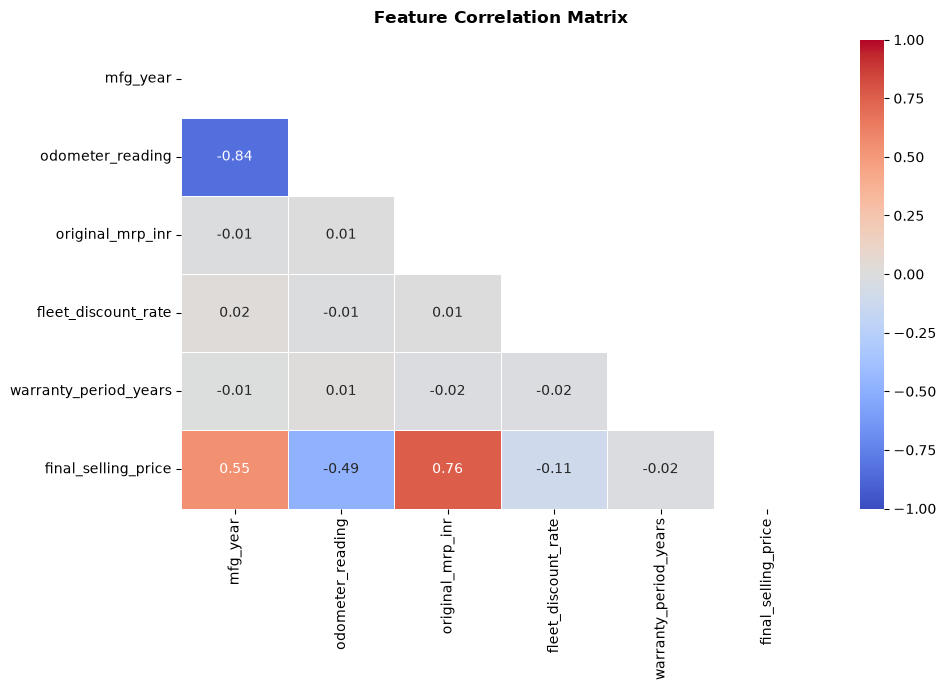

In [10]:
# ------------------------------------------------------------------------------
# STEP 4: BIVARIATE / MULTIVARIATE CORRELATION
# ------------------------------------------------------------------------------
if len(num_cols) > 1:
    plt.figure(figsize=(10, 7))
    corr_matrix = df_cleaned[num_cols].corr()

    # Generate mask for upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        linewidths=0.5
    )
    plt.title("Feature Correlation Matrix", fontweight="bold", pad=12)
    plt.tight_layout()
    plt.show()

C:\Users\Gaurav\AppData\Local\Temp\ipykernel_15760\3865008565.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


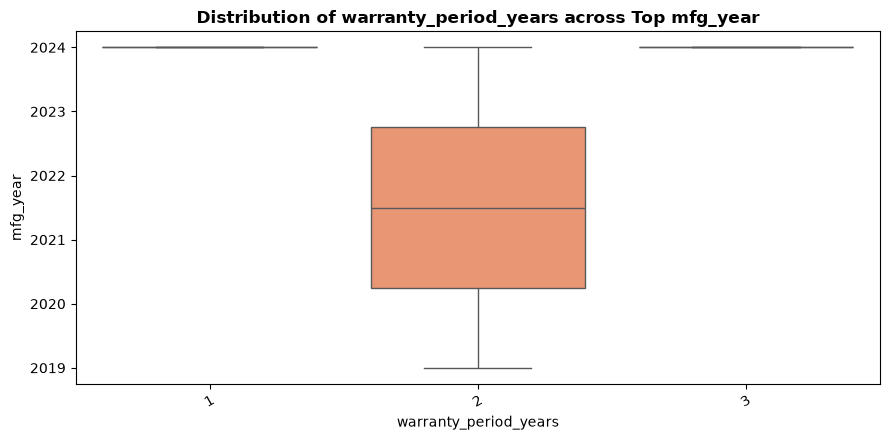

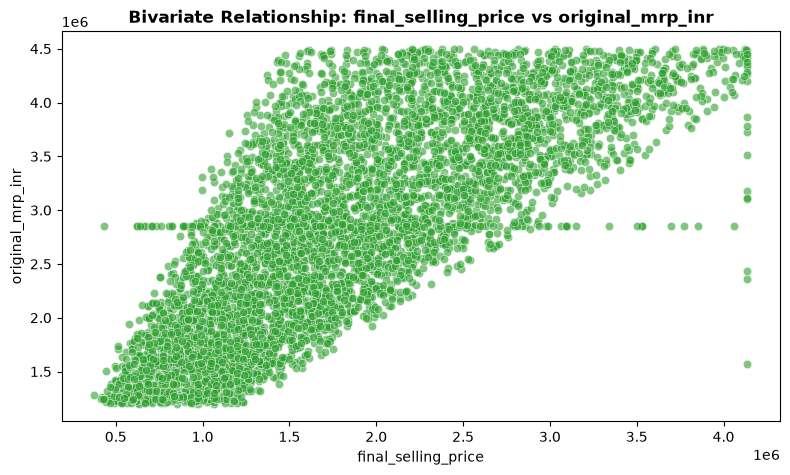

In [11]:
# ------------------------------------------------------------------------------
# STEP 5: RELATIONSHIPS & OUTLIER DETECTION
# ------------------------------------------------------------------------------
# 4. Boxplot: Numerical metric segmented by top categorical group
if len(cat_cols) and len(num_cols):
    plt.figure(figsize=(9, 4.5))
    target_num = num_cols[0]
    sns.boxplot(
        data=df_cleaned[df_cleaned[primary_cat].isin(top_categories[:5])],
        x=num_cols[4],
        y=num_cols[0],
        palette="Set2"
    )
    plt.title(f"Distribution of {num_cols[4]} across Top {num_cols[0]}", fontweight="bold")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# 5. Scatter Plot: Interaction between two key numerical features
if len(num_cols) >= 2:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=df_cleaned,
        x=num_cols[5],
        y=num_cols[2],
        alpha=0.6,
        color="#2ca02c"
    )
    plt.title(f"Bivariate Relationship: {num_cols[5]} vs {num_cols[2]}", fontweight="bold")
    plt.tight_layout()
    plt.show()

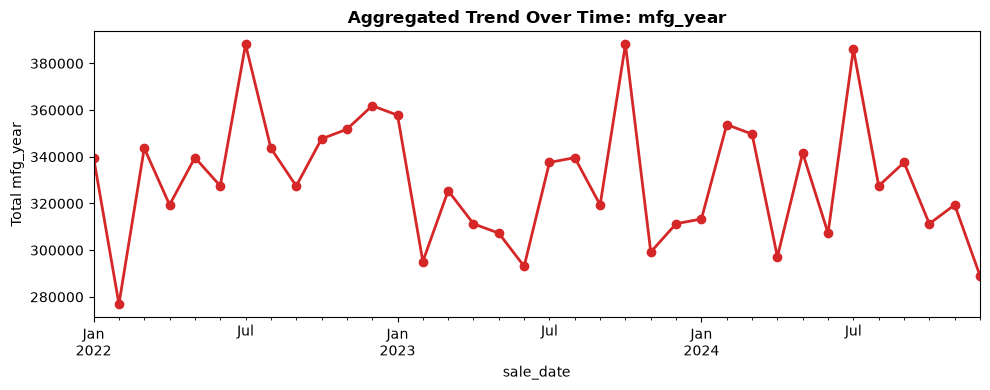


--- GROUPED AGGREGATION TABLE ---


mfg_year               odometer_reading           \
                             mean  median count             mean   median   
transaction_reference_no                                                    
AUTO-30000                 2022.0  2022.0     1          48504.0  48504.0   
AUTO-30001                 2023.0  2023.0     1          42540.0  42540.0   
AUTO-30002                 2021.0  2021.0     1          59164.0  59164.0   
AUTO-30003                 2023.0  2023.0     1          41371.0  41371.0   
AUTO-30004                 2023.0  2023.0     1          39381.0  39381.0   
AUTO-30006                 2021.0  2021.0     1          71658.0  71658.0   
AUTO-30007                 2021.0  2021.0     1          56386.0  56386.0   
AUTO-30008                 2021.0  2021.0     1          46014.0  46014.0   
AUTO-30009                 2023.0  2023.0     1          35234.0  35234.0   
AUTO-30010                 2022.0  2022.0     1          55192.0  55192.0   

                               original_mrp_inr                      
                         count             mean        median count  
transaction_reference_no                                             
AUTO-30000                   1     2.123162e+06  2.123162e+06     1  
AUTO-30001                   1     2.295594e+06  2.295594e+06     1  
AUTO-30002                   1     3.387228e+06  3.387228e+06     1  
AUTO-30003                   1     4.073092e+06  4.073092e+06     1  
AUTO-30004                   1     3.704987e+06  3.704987e+06     1  
AUTO-30006                   1     2.798491e+06  2.798491e+06     1  
AUTO-30007                   1     3.489558e+06  3.489558e+06     1  
AUTO-30008                   1     3.024116e+06  3.024116e+06     1  
AUTO-30009                   1     1.913627e+06  1.913627e+06     1  
AUTO-30010                   1     1.888342e+06  1.888342e+06     1

In [12]:
# ------------------------------------------------------------------------------
# STEP 6: GROUPED AGGREGATIONS & TIME SERIES
# ------------------------------------------------------------------------------
# Check for any date/time column
date_cols = [c for c in df_cleaned.columns if "date" in c.lower() or "time" in c.lower()]

if date_cols:
    time_col = date_cols[0]
    df_temp = df_cleaned.copy()
    df_temp[time_col] = pd.to_datetime(df_temp[time_col], errors="coerce")
    df_temp = df_temp.dropna(subset=[time_col]).sort_values(by=time_col)
    
    # 6. Trend over time (monthly aggregation)
    monthly_trend = df_temp.set_index(time_col)[num_cols[0]].resample("ME").sum()
    plt.figure(figsize=(10, 4))
    monthly_trend.plot(marker="o", color="#d62728", linewidth=2)
    plt.title(f"Aggregated Trend Over Time: {num_cols[0]}", fontweight="bold")
    plt.ylabel(f"Total {num_cols[0]}")
    plt.tight_layout()
    plt.show()

# Group-by table for presentation
if len(cat_cols) and len(num_cols):
    print("\n--- GROUPED AGGREGATION TABLE ---")
    grouped_summary = df_cleaned.groupby(primary_cat)[num_cols[:3]].agg(["mean", "median", "count"])
    display(grouped_summary.head(10))

In [16]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Identify Target Column
target_col = 'sales' if 'sales' in df_cleaned.columns else df_cleaned.select_dtypes(include=[np.number]).columns[-1]
print(f"Target column: {target_col}")

# 2. Drop datetime columns (models cannot process raw dates directly)
df_ready = df_cleaned.copy()
for col in df_ready.columns:
    if pd.api.types.is_datetime64_any_dtype(df_ready[col]) or "date" in col.lower() or "time" in col.lower():
        # Optional: Extract simple numeric features before dropping
        try:
            dt = pd.to_datetime(df_ready[col], errors='coerce')
            df_ready[f'{col}_month'] = dt.dt.month
            df_ready[f'{col}_year'] = dt.dt.year
        except:
            pass
        df_ready = df_ready.drop(columns=[col])

# 3. One-hot encode categorical features (convert to int 0/1 to avoid boolean dtype errors)
df_model = pd.get_dummies(df_ready, drop_first=True, dtype=int)

# 4. Separate features (X) and target (y)
X = df_model.drop(columns=[target_col])
y = df_model[target_col]

# Ensure all columns are numeric
X = X.astype(float)
y = y.astype(float)

# 5. Train/Test Split (80/20)[cite: 1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Target column: final_selling_price


Training features shape: (4704, 5913)
Testing features shape: (1176, 5913)


In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Train Linear Regression Baseline
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

# 2. Train Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

# 3. Evaluate Both Models
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

lr_mae, lr_rmse, lr_r2 = evaluate_model(y_test, lr_preds)
rf_mae, rf_rmse, rf_r2 = evaluate_model(y_test, rf_preds)

# Model evaluation comparison table
metrics_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse],
    'R-squared': [lr_r2, rf_r2]
})

display(metrics_df)

,Model,MAE,RMSE,R-squared
0,Linear Regression,244469.468570,332621.905035,0.820850
1,Random Forest,56993.628863,126720.526493,0.973998


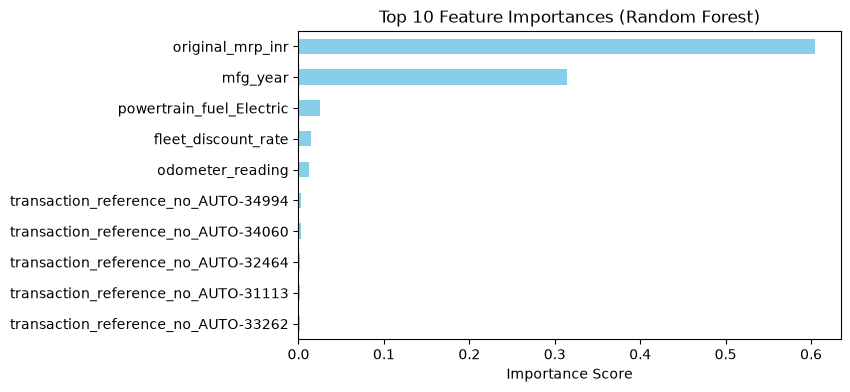

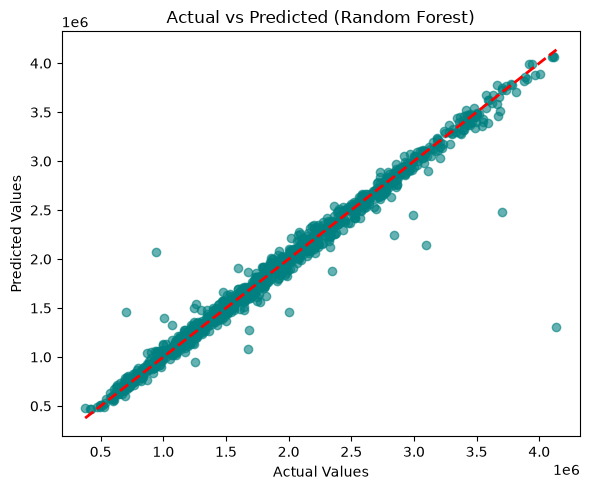

In [19]:
import matplotlib.pyplot as plt

# 1. Feature Importance for Random Forest
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(7, 4))
importances.plot(kind='barh', color='skyblue').invert_yaxis()
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Importance Score')
plt.show()

# 2. Actual vs. Predicted Plot for Best Model
best_preds = rf_preds if rf_r2 >= lr_r2 else lr_preds
model_name = "Random Forest" if rf_r2 >= lr_r2 else "Linear Regression"

plt.figure(figsize=(6, 5))
plt.scatter(y_test, best_preds, alpha=0.6, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title(f'Actual vs Predicted ({model_name})')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.tight_layout()
plt.show()

In [20]:
from sklearn.model_selection import RandomizedSearchCV

# Define parameter grid
param_dist = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5]
}

# Run search
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=5,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)
rf_search.fit(X_train, y_train)

# Evaluate tuned model
best_rf = rf_search.best_estimator_
tuned_preds = best_rf.predict(X_test)
tuned_mae, tuned_rmse, tuned_r2 = evaluate_model(y_test, tuned_preds)

print("Best Parameters:", rf_search.best_params_)
print(f"Tuned Random Forest -> MAE: {tuned_mae:.2f}, RMSE: {tuned_rmse:.2f}, R2: {tuned_r2:.4f}")

Best Parameters: {'n_estimators': 50, 'min_samples_split': 2, 'max_depth': None}
Tuned Random Forest -> MAE: 58002.29, RMSE: 128482.04, R2: 0.9733
